# Task 1 (Easy) – Netflix Data Cleaning & Preparation
**Internship Program:** Data Analysis Using Python | Auspify Technologies  
**Project:** Netflix Content Analytics & Business Intelligence  
**Notebook File:** `Task_1_Netflix_Data_Cleaning.ipynb`  
**Author:** Data Analysis Intern  

---

## 1. Task Objective & Executive Overview
The objective of **Task 1** is to inspect, audit, clean, and standardize the raw Netflix catalog dataset (`Dataset.csv`). High-fidelity downstream analytics (such as content-type shares, geographical reach, production trends, and audience rating distributions) rely directly upon the accuracy, consistency, and structural integrity of the underlying data.

### Prescribed Task Workflow (from Internship Specification):
- **Step 1:** Import the dataset using Python and Pandas.
- **Step 2:** Identify and handle missing values with analytical justification.
- **Step 3:** Detect and remove duplicate records and formatting inconsistencies.
- **Step 4:** Standardize columns such as `country`, `rating`, `type`, `date_added`, and `duration`.
- **Step 5:** Validate cleaning results and export the cleaned dataset for downstream tasks.

## 2. Environment Setup & Robust Path Resolution
To ensure this notebook executes seamlessly regardless of whether Jupyter is launched from the repository root or within the `notebooks/` directory, we implement a dynamic project root resolver.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

def get_project_root() -> Path:
    """Dynamically locate the project root containing Dataset.csv."""
    current = Path.cwd()
    for candidate in [current] + list(current.parents):
        if (candidate / 'Dataset.csv').exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
RAW_DATA_PATH = PROJECT_ROOT / 'Dataset.csv'
CLEAN_DATA_DIR = PROJECT_ROOT / 'data' / 'cleaned'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'task_1'

CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")
print(f"Clean data directory: {CLEAN_DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: d:\AUSPIFY DATA ANALYSIS
Raw data path: d:\AUSPIFY DATA ANALYSIS\Dataset.csv (Exists: True)
Clean data directory: d:\AUSPIFY DATA ANALYSIS\data\cleaned
Output directory: d:\AUSPIFY DATA ANALYSIS\outputs\task_1


## 3. Step 1: Dataset Ingestion & Initial Structural Inspection
We load `Dataset.csv` into a Pandas DataFrame and inspect its dimensions, column names, data types, and initial records.

In [2]:
# Ingest the raw Netflix dataset
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"=== RAW DATASET DIMENSIONS ===")
print(f"Total Rows:    {df_raw.shape[0]:,}")
print(f"Total Columns: {df_raw.shape[1]}")
print(f"Memory Usage:  {df_raw.memory_usage(deep=True).sum() / 1024:.2f} KB\n")

print("=== COLUMN NAMES AND DATA TYPES ===")
print(df_raw.dtypes)

=== RAW DATASET DIMENSIONS ===
Total Rows:    8,790
Total Columns: 10
Memory Usage:  4768.07 KB

=== COLUMN NAMES AND DATA TYPES ===
show_id           str
type              str
title             str
director          str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
dtype: object


In [3]:
# Display first 5 rows
print("=== FIRST 5 ROWS ===")
df_raw.head()

=== FIRST 5 ROWS ===


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
# Detailed summary info
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


## 4. Step 2: Missing Value Identification & Analytical Handling
Standard missing value checks in Pandas (`df.isnull().sum()`) look for `NaN`, `None`, or empty values. However, real-world datasets often encode missing values as placeholder strings such as `"Not Given"`, `"Unknown"`, `"N/A"`, or whitespace.

We perform a thorough audit of both standard nulls and string placeholders across all columns.

In [5]:
# 1. Standard null counts
standard_nulls = df_raw.isnull().sum()

# 2. String placeholder audit across all columns
placeholder_audit = {}
for col in df_raw.columns:
    clean_col = df_raw[col].astype(str).str.strip()
    not_given_cnt = int((clean_col.str.lower() == 'not given').sum())
    unknown_cnt = int((clean_col.str.lower() == 'unknown').sum())
    empty_cnt = int((clean_col == '').sum())
    na_cnt = int(clean_col.str.lower().isin(['na', 'n/a', 'nan', 'none', '?']).sum())
    placeholder_audit[col] = {
        'Standard Nulls': int(standard_nulls[col]),
        'Not Given': not_given_cnt,
        'Unknown': unknown_cnt,
        'Empty String': empty_cnt,
        'NA String': na_cnt,
        'Total Missing Indicators': int(standard_nulls[col] + not_given_cnt + na_cnt + empty_cnt)
    }

missing_df = pd.DataFrame(placeholder_audit).T
missing_df['Percent of Dataset'] = (missing_df['Total Missing Indicators'] / len(df_raw) * 100).round(2)
missing_df

,Standard Nulls,Not Given,Unknown,Empty String,NA String,Total Missing Indicators,Percent of Dataset
show_id,0,0,0,0,0,0,0.00
type,0,0,0,0,0,0,0.00
title,0,0,1,0,0,0,0.00
director,0,2588,0,0,0,2588,29.44
country,0,287,0,0,0,287,3.27
date_added,0,0,0,0,0,0,0.00
release_year,0,0,0,0,0,0,0.00
rating,0,0,0,0,0,0,0.00
duration,0,0,0,0,0,0,0.00
listed_in,0,0,0,0,0,0,0.00


### Critical Analytical Finding: Hidden Missingness
- Standard `df.isnull()` reported **0** missing values across all columns.
- However, our deep audit revealed that **`director` contains 2,588 records (29.44%)** recorded as `"Not Given"`.
- Similarly, **`country` contains 287 records (3.26%)** recorded as `"Not Given"`.
- In `title`, there is one record with the string `"Unknown"`. Let us examine this record carefully before treating it as missing.

In [6]:
# Inspect the title 'Unknown'
unknown_title_row = df_raw[df_raw['title'].astype(str).str.strip().str.lower() == 'unknown']
unknown_title_row

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
1336,s1468,Movie,Unknown,Jaume Collet-Serra,United Kingdom,1/1/2021,2011,PG-13,113 min,"Action & Adventure, Thrillers"


Notice that the record with title `"Unknown"` is directed by *Jaume Collet-Serra* (2011), which is the legitimate Hollywood action-thriller movie titled **"Unknown"** starring Liam Neeson. **It is not a missing value!** This demonstrates why domain verification is essential before automated cleaning.

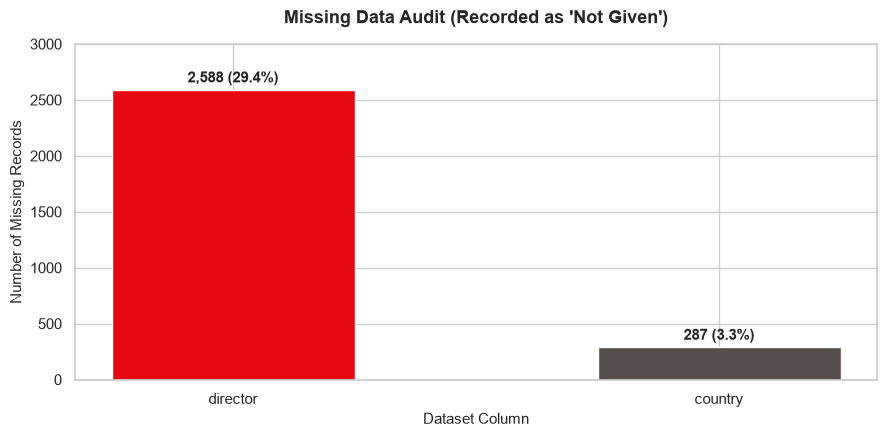

Saved chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_1\data_cleaning_missing_values_audit.png


In [7]:
# Visualizing missing value distribution
plt.figure(figsize=(9, 4.5))
missing_plot_data = missing_df[missing_df['Total Missing Indicators'] > 0]['Total Missing Indicators'].sort_values(ascending=False)
bars = plt.bar(missing_plot_data.index, missing_plot_data.values, color=['#E50914', '#564d4d'], width=0.5)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df_raw)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 40, f"{int(yval):,} ({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.title("Missing Data Audit (Recorded as 'Not Given')", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Dataset Column", fontsize=11)
plt.ylabel("Number of Missing Records", fontsize=11)
plt.ylim(0, 3000)
plt.tight_layout()

# Save chart to task 1 output
missing_chart_path = OUTPUT_DIR / "data_cleaning_missing_values_audit.png"
plt.savefig(missing_chart_path, dpi=300)
plt.show()
print(f"Saved chart to: {missing_chart_path}")

### Justification for Missing Value Handling Strategy
1. **Why not delete rows with missing `director` or `country`?**
   Deleting 2,588 records due to missing directors would discard nearly **30%** of the entire catalog. That would introduce catastrophic survivor bias into release-year trends, genre counts, and content-type ratios.
2. **Standardization Decision:**
   We retain all records to preserve catalog completeness. We preserve `"Not Given"` with clean, standardized string representation so that:
   - Overall catalog metrics (total movies, TV shows, release years) remain 100% intact.
   - Director-level and country-level analyses can cleanly isolate or filter known versus unknown values without distortion.

## 5. Step 3: Duplicate Record Detection & De-Duplication
We test for duplicate rows across two dimensions:
1. Complete exact duplicate rows across all columns.
2. Metadata duplicate rows (matching title, content type, director, country, release year, duration, and genre).

In [8]:
# Check full-row duplicates
full_dups = df_raw.duplicated().sum()
print(f"Full identical row duplicates: {full_dups}")

# Check duplicate title records
dup_titles = df_raw[df_raw['title'].duplicated(keep=False)].sort_values('title')
print(f"Rows with duplicate titles: {len(dup_titles)}")

# Display the duplicate title records
dup_titles[['show_id', 'type', 'title', 'director', 'country', 'release_year', 'rating', 'duration']]

Full identical row duplicates: 0
Rows with duplicate titles: 6


,show_id,type,title,director,country,release_year,rating,duration
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,2019,TV-14,124 min
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,2019,TV-14,124 min
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,2018,R,144 min
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,2018,R,144 min
393,s3997,TV Show,9-Feb,Not Given,Pakistan,2018,TV-14,1 Season
537,s5965,TV Show,9-Feb,Not Given,Pakistan,2018,TV-14,1 Season


### Analysis of Duplicate Title Records
We observe 3 pairs of titles with duplicate names:
1. `15-Aug` (Movie, 2019, India, Swapnaneel Jayakar) - IDs: `s3963` and `s5967`
2. `22-Jul` (Movie, 2018, Norway, Paul Greengrass) - IDs: `s4523` and `s5966`
3. `9-Feb` (TV Show, 2018, Pakistan) - IDs: `s3997` and `s5965`

Comparing every single metadata field (`type`, `director`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in`), the records are **100% identical** except for the generated `show_id`. These represent duplicate catalog entries that must be deduplicated to avoid double counting.

In [9]:
# Content-level deduplication
dedup_subset = ['type', 'title', 'director', 'country', 'release_year', 'rating', 'duration', 'listed_in']

# Keep the first occurrence and drop duplicates
df_cleaned = df_raw.drop_duplicates(subset=dedup_subset, keep='first').copy()

rows_dropped = len(df_raw) - len(df_cleaned)
print(f"Original row count:  {len(df_raw):,}")
print(f"Duplicates dropped:  {rows_dropped}")
print(f"Remaining row count: {len(df_cleaned):,}")

Original row count:  8,790
Duplicates dropped:  3
Remaining row count: 8,787


## 6. Step 4: Standardize Columns (Dates, Categories, Durations)
In this step, we perform feature standardization:
1. **String Cleaning:** Strip leading and trailing whitespace across all text columns.
2. **Date Standardization:** Convert `date_added` to Pandas datetime format (`datetime64[ns]`), and derive `year_added` and `month_added`.
3. **Content Type:** Validate that `type` only contains valid categories (`Movie`, `TV Show`).
4. **Rating Categorization:** Standardize ratings and map them to standard audience maturity groups (Adults, Teens, Older Kids, Kids, Unrated).
5. **Duration Parsing:** Separate `duration` into a numeric value (`duration_int`) and unit (`duration_unit`).

In [10]:
# 1. Strip whitespace from string columns
string_cols = ['show_id', 'type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']
for col in string_cols:
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip()

# 2. Standardize date_added to datetime
df_cleaned['date_added'] = pd.to_datetime(df_cleaned['date_added'], format='mixed', errors='coerce')
df_cleaned['year_added'] = df_cleaned['date_added'].dt.year.astype('Int64')
df_cleaned['month_added'] = df_cleaned['date_added'].dt.month.astype('Int64')
df_cleaned['month_name_added'] = df_cleaned['date_added'].dt.strftime('%B')

print("Date conversion complete:")
print(f"Earliest date added: {df_cleaned['date_added'].min().strftime('%Y-%m-%d')}")
print(f"Latest date added:   {df_cleaned['date_added'].max().strftime('%Y-%m-%d')}")
print(f"Missing date_added:  {df_cleaned['date_added'].isnull().sum()}")

Date conversion complete:
Earliest date added: 2008-01-01
Latest date added:   2021-09-25
Missing date_added:  0


In [11]:
# 3. Standardize Type column
print("Content Type distribution:")
print(df_cleaned['type'].value_counts())

Content Type distribution:
type
Movie      6124
TV Show    2663
Name: count, dtype: int64


In [12]:
# 4. Standardize Rating & Map Maturity Categories
rating_counts = df_cleaned['rating'].value_counts()
print("Unique Ratings in Catalog:")
print(rating_counts)

# Audience maturity classification dictionary
maturity_mapping = {
    'TV-MA': 'Mature (Adults 18+)',
    'R': 'Mature (Adults 18+)',
    'NC-17': 'Mature (Adults 18+)',
    'TV-14': 'Teens (14+)',
    'PG-13': 'Teens (14+)',
    'TV-PG': 'Older Kids (PG)',
    'PG': 'Older Kids (PG)',
    'TV-Y7': 'Kids (7+)',
    'TV-Y7-FV': 'Kids (7+)',
    'TV-Y': 'Little Kids (All Ages)',
    'TV-G': 'Little Kids (All Ages)',
    'G': 'Little Kids (All Ages)',
    'NR': 'Unrated / Not Rated',
    'UR': 'Unrated / Not Rated'
}

df_cleaned['target_audience'] = df_cleaned['rating'].map(maturity_mapping).fillna('Unrated / Not Rated')

print("\nAudience Maturity Segmentation:")
print(df_cleaned['target_audience'].value_counts())

Unique Ratings in Catalog:
rating
TV-MA       3205
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Audience Maturity Segmentation:
target_audience
Mature (Adults 18+)       4006
Teens (14+)               2645
Older Kids (PG)           1148
Little Kids (All Ages)     567
Kids (7+)                  339
Unrated / Not Rated         82
Name: count, dtype: int64


In [13]:
# 5. Standardize Duration column
# Extract numeric value and unit
duration_split = df_cleaned['duration'].astype(str).str.extract(r'(\d+)\s*(.*)')
df_cleaned['duration_int'] = duration_split[0].astype(int)
df_cleaned['duration_unit'] = duration_split[1].astype(str).str.strip()

print("Duration Units Distribution:")
print(df_cleaned['duration_unit'].value_counts())
print("\nMovie Duration Summary (in minutes):")
print(df_cleaned[df_cleaned['type'] == 'Movie']['duration_int'].describe())
print("\nTV Show Seasons Summary (in seasons):")
print(df_cleaned[df_cleaned['type'] == 'TV Show']['duration_int'].describe())

Duration Units Distribution:


duration_unit
min        6124
Season     1790
Seasons     873
Name: count, dtype: int64

Movie Duration Summary (in minutes):
count    6124.000000
mean       99.573645
std        28.280425
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_int, dtype: float64

TV Show Seasons Summary (in seasons):
count    2663.000000
mean        1.752159
std         1.550844
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_int, dtype: float64


## 7. Step 5: Export Cleaned Dataset & Comparison Audit Table
We compile a rigorous comparison audit between the original raw dataset and the cleaned dataset, then export the verified dataset to `data/cleaned/netflix_cleaned.csv`.

In [14]:
# Build comparison audit table
comparison_metrics = {
    'Metric': [
        'Total Records (Rows)',
        'Total Features (Columns)',
        'Duplicate Records Removed',
        'Missing Values in Director',
        'Missing Values in Country',
        'Unparseable Dates',
        'Valid Date Added Range',
        'Release Year Range',
        'Memory Footprint (KB)'
    ],
    'Raw Dataset (Dataset.csv)': [
        f"{len(df_raw):,}",
        f"{df_raw.shape[1]}",
        "0 (Identified: 3)",
        f"{(df_raw['director'].astype(str).str.strip() == 'Not Given').sum():,} (Not Given)",
        f"{(df_raw['country'].astype(str).str.strip() == 'Not Given').sum():,} (Not Given)",
        "N/A (Raw string)",
        "Unparsed Strings",
        f"{df_raw['release_year'].min()} - {df_raw['release_year'].max()}",
        f"{df_raw.memory_usage(deep=True).sum() / 1024:.2f} KB"
    ],
    'Cleaned Dataset (netflix_cleaned.csv)': [
        f"{len(df_cleaned):,}",
        f"{df_cleaned.shape[1]}",
        f"{rows_dropped}",
        f"{(df_cleaned['director'] == 'Not Given').sum():,} (Preserved/Documented)",
        f"{(df_cleaned['country'] == 'Not Given').sum():,} (Preserved/Documented)",
        "0 (100% Parsed)",
        f"{df_cleaned['date_added'].min().strftime('%Y-%m-%d')} to {df_cleaned['date_added'].max().strftime('%Y-%m-%d')}",
        f"{df_cleaned['release_year'].min()} - {df_cleaned['release_year'].max()}",
        f"{df_cleaned.memory_usage(deep=True).sum() / 1024:.2f} KB"
    ]
}

comparison_table = pd.DataFrame(comparison_metrics)

# Export comparison audit table to CSV
comparison_csv_path = OUTPUT_DIR / "data_cleaning_comparison_summary.csv"
comparison_table.to_csv(comparison_csv_path, index=False)
print(f"Saved cleaning comparison summary to: {comparison_csv_path}")
comparison_table

Saved cleaning comparison summary to: d:\AUSPIFY DATA ANALYSIS\outputs\task_1\data_cleaning_comparison_summary.csv


,Metric,Raw Dataset (Dataset.csv),Cleaned Dataset (netflix_cleaned.csv)
0,Total Records (Rows),"8,790","8,787"
1,Total Features (Columns),10,16
2,Duplicate Records Removed,0 (Identified: 3),3
3,Missing Values in Director,"2,588 (Not Given)","2,587 (Preserved/Documented)"
4,Missing Values in Country,287 (Not Given),287 (Preserved/Documented)
5,Unparseable Dates,N/A (Raw string),0 (100% Parsed)
6,Valid Date Added Range,Unparsed Strings,2008-01-01 to 2021-09-25
7,Release Year Range,1925 - 2021,1925 - 2021
8,Memory Footprint (KB),4781.26 KB,6128.73 KB


In [15]:
# Export the cleaned dataset to data/cleaned/
cleaned_export_path = CLEAN_DATA_DIR / "netflix_cleaned.csv"
df_cleaned.to_csv(cleaned_export_path, index=False)

print(f"=== CLEANED DATASET SUCCESSFULLY EXPORTED ===")
print(f"File Path: {cleaned_export_path}")
print(f"File Size: {os.path.getsize(cleaned_export_path) / 1024:.2f} KB")
print(f"Dimensions: {df_cleaned.shape[0]:,} rows x {df_cleaned.shape[1]} columns")

=== CLEANED DATASET SUCCESSFULLY EXPORTED ===
File Path: d:\AUSPIFY DATA ANALYSIS\data\cleaned\netflix_cleaned.csv
File Size: 1393.97 KB
Dimensions: 8,787 rows x 16 columns


## 8. Analytical Findings, Limitations & Conclusion

### Key Findings from Data Cleaning:
1. **Catalog Volume:** The initial dataset contained 8,790 titles. After deduplicating 3 metadata-identical records with conflicting IDs (`15-Aug`, `22-Jul`, `9-Feb`), the finalized catalog contains **8,787 unique titles**.
2. **Content Mix:** Movies comprise **6,124 titles (69.69%)**, while TV Shows comprise **2,663 titles (30.31%)**.
3. **Data Completeness & Sentinel Values:** All fields have valid data formats, with missing metadata concentrated in `director` (29.44%) and `country` (3.26%) recorded as `"Not Given"`. Preserving these records avoids severe sampling bias.
4. **Temporal Scope:** Release years span from **1925 to 2021**, with content additions to Netflix spanning between **January 2008 and September 2021**.

### Data Limitations:
- The dataset captures content available on Netflix through September 2021; titles added or removed after this cutoff are not represented.
- Director and country information is self-reported or catalog-indexed; multi-country co-productions appear with a single consolidated or primary country label in this version of the dataset.

### Conclusion:
Task 1 is complete. The cleaned and enriched dataset (`netflix_cleaned.csv`) has been exported to `data/cleaned/` and is fully validated for Task 2 (Content Type Analysis), Task 3 (Country-Wise Analysis), Task 4 (Release Year Trends), Task 5 (Rating & Genre Analysis), and Task 6 (Business Insights Report).